# Companion notebook — Comparative analysis of AI methods for the estimation of individual electricity consumption

This is the anonymized companion artifact of the paper (under double-blind review). It reproduces, end to end:

- Table 1 — naive and statistical baselines (persistence, seasonal 24h/48h, Holt-Winters additive/damped);
- Tables 2–4 — six learning models (Decision Tree, Random Forest, XGBoost, LSTM, TCN, Transformer) under three feature configurations (univariate, seasonal, sensor-based), with 95% bootstrap confidence intervals and Diebold-Mariano tests against the naive seasonal 24h baseline;
- the paired cross-configuration and between-model significance tests discussed in the paper;
- the paper figures: `fig_baselines.png`, `fig_forecast_uni.png`, `fig_config_comparison.png`, `fig_hourly_mae.png` (all saved at 300 dpi).

The dataset is the 30-minute electricity consumption series of a single household (18 months), enriched with an indoor environmental sensor (BME680: temperature, humidity, pressure, air quality), the outdoor temperature of a national weather station, and cyclic calendar encodings. All values are in kWh.

Expected runtime: roughly 30–60 minutes on a free Google Colab GPU session (T4), most of it spent training the three deep models on the three configurations. Note that the exact figures of the paper were obtained on different hardware and library versions; re-running this notebook may yield slightly different point estimates, while the qualitative conclusions are stable. The results file of the paper's run is provided alongside this notebook in the repository.


## 1. Requirements and configuration


In [ ]:
# ----- Requirements -----
# (run once per session; on Colab xgboost and gdown are pre-installed but pinned here
#  for reproducibility — check the printed versions against the README of the repository)
import importlib

def _ensure(pkg, pip_name=None):
    try:
        importlib.import_module(pkg)
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name or pkg])

_ensure('xgboost')

import os, time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb

# ----- Library versions (report these when citing results) -----
import sklearn, scipy, matplotlib
print('numpy       ', np.__version__)
print('pandas      ', pd.__version__)
print('scipy       ', scipy.__version__)
print('scikit-learn', sklearn.__version__)
print('xgboost     ', xgb.__version__)
print('torch       ', torch.__version__)
print('matplotlib  ', matplotlib.__version__)

# ----- Global constants -----
TARGET_COL = 'Consumption'   # 30-min electricity consumption in kWh
LOOKBACK = 48                 # 24 h of history
HORIZON = 48                  # next 24 h to predict
SEASONAL_PERIOD = 48         # daily period in 30-min steps (Holt-Winters)
BATCH_SIZE = 64
EPOCHS = 100
LR = 1e-3
SEED = 42

# Evaluation protocol
N_BOOTSTRAP = 1000           # bootstrap replicates for confidence intervals
CI_LEVEL = 0.95
MAPE_EPS = 0.05              # kWh exclusion threshold for the MAPE
HAC_LAG = HORIZON - 1        # Newey-West lags for the Diebold-Mariano variance

# Single forecast origin shared by all paper figures
FIG_INDEX = 168              # keep consistent across figures (see paper, section 4)

np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

plt.rcParams.update({'font.size': 12, 'axes.titlesize': 13, 'axes.labelsize': 12})


numpy        2.4.6
pandas       2.2.3
scipy        1.16.3
scikit-learn 1.6.1
xgboost      3.4.1
torch        2.14.1+cu130
matplotlib   3.10.0
Device: cuda


## 2. Data loading

The dataset is fetched from the anonymized repository accompanying the paper. Fill `DATA_URL` with the direct download link of the `combined.csv` file. The CSV contains one row per 30-minute step, indexed by `DateTime`, with: the smart meter consumption (`Consommation`, kWh), the indoor BME680 channels (`Temperature`, `Pression`, `Humidity`, `AirQuality`), and the outdoor temperature of the weather station (`Prunay`, Kelvin).


In [ ]:
import urllib.request

DATA_URL = 'https://anonymous.4open.science/api/repo/energy_consumption-64E2/file/combined.csv'
LOCAL_FALLBACK = 'combined.csv'   # if the file is already in the working directory

if not os.path.exists(LOCAL_FALLBACK):
    assert DATA_URL, ('DATA_URL is empty and %s not found. Set DATA_URL to the direct '
                      'download link of the dataset file provided in the repository.' % LOCAL_FALLBACK)
    print('Downloading dataset...')
    # Note: the repository API rejects the default 'Python-urllib' User-Agent
    # (HTTP 403), so the request is made with a browser-like User-Agent.
    # The API is rate-limited (~175 requests / 15 min), so the file is cached locally.
    req = urllib.request.Request(DATA_URL, headers={'User-Agent': 'Mozilla/5.0 (companion-notebook)'})
    with urllib.request.urlopen(req, timeout=120) as r, open(LOCAL_FALLBACK, 'wb') as f:
        f.write(r.read())
assert os.path.exists(LOCAL_FALLBACK), 'Dataset download failed.'
print('Dataset ready:', LOCAL_FALLBACK)

Dataset ready: combined.csv


In [ ]:
df_consumption = pd.read_csv(LOCAL_FALLBACK, parse_dates=['DateTime'], index_col='DateTime')

# English column names (the CSV keeps the original French names)
df_consumption = df_consumption.rename(columns={
    'Consommation': 'Consumption',
    'Pression': 'Pressure',
    'Prunay': 'OutdoorTemp',      # weather station, Kelvin -> Celsius below
})

print('Outdoor temp (K): min=%.1f, max=%.1f' % (df_consumption['OutdoorTemp'].min(),
                                               df_consumption['OutdoorTemp'].max()))
df_consumption['OutdoorTemp'] = df_consumption['OutdoorTemp'] - 273.15
print('Outdoor temp (C): min=%.1f, max=%.1f' % (df_consumption['OutdoorTemp'].min(),
                                               df_consumption['OutdoorTemp'].max()))

if df_consumption.index.duplicated().any():
    print('Removing %d duplicated timestamps...' % df_consumption.index.duplicated().sum())
    df_consumption = df_consumption[~df_consumption.index.duplicated(keep='first')]
df_consumption = df_consumption.asfreq('30min', method='ffill')

# Cyclic calendar encodings (sine/cosine), as described in the paper.
# If the CSV already contains the encoded columns, they are used as-is; otherwise
# they are recomputed from the timestamp index with the formulas below.
_encoded = ['hour_sin', 'hour_cos', 'minute_sin', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos']
if all(c in df_consumption.columns for c in _encoded):
    print('Cyclic calendar encodings: found in the CSV, used as-is.')
else:
    _idx = df_consumption.index
    df_consumption['hour_sin'] = np.sin(2 * np.pi * _idx.hour / 24)
    df_consumption['hour_cos'] = np.cos(2 * np.pi * _idx.hour / 24)
    df_consumption['minute_sin'] = np.sin(2 * np.pi * (_idx.hour * 60 + _idx.minute) / 1440)
    df_consumption['weekday_sin'] = np.sin(2 * np.pi * _idx.dayofweek / 7)
    df_consumption['weekday_cos'] = np.cos(2 * np.pi * _idx.dayofweek / 7)
    df_consumption['month_sin'] = np.sin(2 * np.pi * _idx.month / 12)
    df_consumption['month_cos'] = np.cos(2 * np.pi * _idx.month / 12)
    print('Cyclic calendar encodings: recomputed from the index.')

print('Shape:', df_consumption.shape)
print('Period:', df_consumption.index.min(), '->', df_consumption.index.max())
print('Columns:', list(df_consumption.columns))


Outdoor temp (K): min=265.6, max=311.1
Outdoor temp (C): min=-7.6, max=37.9
Removing 4 duplicated timestamps...
Cyclic calendar encodings: found in the CSV, used as-is.
Shape: (26640, 13)
Period: 2024-06-18 00:00:00 -> 2025-12-24 23:30:00
Columns: ['Consumption', 'Temperature', 'Pressure', 'Humidity', 'AirQuality', 'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos', 'minute_sin', 'OutdoorTemp']


## 3. Common functions


In [ ]:
FEATURE_SETS = {
    'univariate': [TARGET_COL],
    'seasonal': [
        TARGET_COL, 'hour_sin', 'hour_cos',
        'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos'
    ],
    'full': [
        TARGET_COL, 'Temperature', 'Pressure', 'Humidity', 'AirQuality',
        'hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos',
        'month_sin', 'month_cos', 'minute_sin', 'OutdoorTemp'
    ],
}

MODEL_ORDER = ['DecisionTree', 'RandomForest', 'XGBoost', 'LSTM', 'TCN', 'Transformer']
STAT_ORDER = ['HoltWinters-Add', 'HoltWinters-Damped']
BASELINE_ORDER = ['NaivePersistence', 'NaiveSeasonal24h', 'NaiveSeasonal48h']
ALL_ORDERED = BASELINE_ORDER[:2] + STAT_ORDER + MODEL_ORDER  # display order (48h kept apart)

# Global registries
all_results = {}
all_predictions = {}
all_truth = {}
all_ci = {}
all_profiles = {}
all_dm = {}


In [ ]:
def temporal_split(df):
    n = len(df)
    train_end, val_end = int(0.6 * n), int(0.8 * n)
    return df.iloc[:train_end], df.iloc[train_end:val_end], df.iloc[val_end:], (train_end, val_end)

def make_windows(data, target_idx, lookback=LOOKBACK, horizon=HORIZON):
    X, y = [], []
    for i in range(lookback, len(data) - horizon + 1):
        X.append(data[i - lookback:i])
        y.append(data[i:i + horizon, target_idx])
    return np.array(X), np.array(y)

def prepare_config(features):
    cols = list(features)
    target_idx = cols.index(TARGET_COL)

    train_df, val_df, test_df, _ = temporal_split(df_consumption[cols])

    scaler_x = MinMaxScaler().fit(train_df[cols])
    scaler_y = MinMaxScaler().fit(train_df[[TARGET_COL]])

    train_s = scaler_x.transform(train_df[cols])
    val_s = scaler_x.transform(pd.concat([train_df[cols].iloc[-LOOKBACK:], val_df[cols]]))
    test_s = scaler_x.transform(pd.concat([val_df[cols].iloc[-LOOKBACK:], test_df[cols]]))

    X_train, y_train = make_windows(train_s, target_idx)
    X_val, y_val = make_windows(val_s, target_idx)
    X_test, y_test = make_windows(test_s, target_idx)

    return {
        'scaler_x': scaler_x, 'scaler_y': scaler_y,
        'X_train': X_train, 'y_train': y_train,
        'X_val': X_val, 'y_val': y_val,
        'X_test': X_test, 'y_test': y_test,
        'test_df': test_df, 'target_idx': target_idx,
    }


In [ ]:
def compute_metrics(real, pred):
    """RMSE, MAE, MAPE (targets >= MAPE_EPS only), sMAPE."""
    real = np.asarray(real, dtype=float)
    pred = np.clip(np.asarray(pred, dtype=float), a_min=0.0, a_max=None)
    r, p = real.flatten(), pred.flatten()

    rmse = float(np.sqrt(mean_squared_error(r, p)))
    mae = float(mean_absolute_error(r, p))

    mask = r >= MAPE_EPS
    mape = float(np.mean(np.abs((r[mask] - p[mask]) / r[mask]))) if mask.any() else np.nan
    mape_excl = float(1.0 - mask.mean())

    denom = (np.abs(r) + np.abs(p)) / 2.0
    smape = float(np.nanmean(np.abs(r - p) / np.where(denom == 0, np.nan, denom)))

    return {'rmse': rmse, 'mae': mae, 'mape': mape, 'smape': smape, 'mape_excl': mape_excl}

def print_metrics(name, m):
    print("  %-20s RMSE: %.3f  MAE: %.3f  MAPE: %.2f%% (excl %.1f%%)  sMAPE: %.2f%%"
          % (name, m['rmse'], m['mae'], m['mape'] * 100, m['mape_excl'] * 100, m['smape'] * 100))


In [ ]:
def metric_on_subset(metric, real_sub, pred_sub, clip=True):
    """Metric on a (possibly bootstrapped) subset of test sequences.
    Non-negativity is enforced on both sides of the pipeline (prediction and metric)."""
    r = np.asarray(real_sub).flatten()
    p = np.asarray(pred_sub).flatten()
    if clip:
        p = np.clip(p, a_min=0.0, a_max=None)
    if metric == 'rmse':
        return float(np.sqrt(np.mean((r - p) ** 2)))
    if metric == 'mae':
        return float(np.mean(np.abs(r - p)))
    if metric == 'mape':
        mask = r >= MAPE_EPS
        return float(np.mean(np.abs((r[mask] - p[mask]) / r[mask]))) if mask.any() else np.nan
    raise ValueError(metric)

def bootstrap_ci(real, pred, metric, n_boot=N_BOOTSTRAP, level=CI_LEVEL, seed=SEED):
    """Bootstrap confidence interval by resampling test forecast sequences."""
    rng = np.random.default_rng(seed)
    n_seq = real.shape[0]
    stats_boot = np.empty(n_boot)
    for b in range(n_boot):
        i = rng.integers(0, n_seq, size=n_seq)
        stats_boot[b] = metric_on_subset(metric, real[i], pred[i])
    alpha = (1 - level) / 2
    lo, hi = np.quantile(stats_boot, [alpha, 1 - alpha])
    return float(lo), float(hi)

def format_ci(lo, hi):
    return "[%.3f, %.3f]" % (lo, hi)


In [ ]:
def diebold_mariano(real, pred_a, pred_b, loss='squared', lag=HAC_LAG):
    """Diebold-Mariano test (Newey-West HAC long-run variance, HLN small-sample correction).
    Returns (statistic, p-value). A negative statistic means model A has a lower loss."""
    real = np.asarray(real, dtype=float)
    ea, eb = np.asarray(pred_a) - real, np.asarray(pred_b) - real
    if loss == 'squared':
        d = ea ** 2 - eb ** 2
    elif loss == 'absolute':
        d = np.abs(ea) - np.abs(eb)
    else:
        raise ValueError(loss)
    d = d.flatten()
    n = len(d)
    dbar = d.mean()

    gamma0 = np.mean((d - dbar) ** 2)
    lr_var = gamma0
    for l in range(1, lag + 1):
        w = 1.0 - l / (lag + 1.0)
        gamma_l = np.mean((d[l:] - dbar) * (d[:-l] - dbar))
        lr_var += 2.0 * w * gamma_l
    lr_var = max(lr_var, 1e-12)

    dm = dbar / np.sqrt(lr_var / n)
    h = n / (1 + 2 * lag) if lag > 0 else n
    corrected = dm * np.sqrt((h + 1) / (h - 1)) if h > 1 else dm
    p_value = 2.0 * (1.0 - stats.t.cdf(np.abs(corrected), df=max(h - 1, 1)))
    return float(dm), float(p_value)


### 3.1 Naive baselines

Rebuilt directly from the raw consumption series (kWh), without going through the normalized windows. Alignment: sequence `idx` predicts test steps `[idx : idx+48]`; the last observation before that origin is `series[LOOKBACK + idx - 1]` (t-1) — the persistence level — while the naive seasonal 24h baseline copies `series[idx : idx+48]` (the previous day, same slots). A cross-check against the normalized windows (assertions below) guarantees that no forecast origin is misaligned.


In [ ]:
def compute_baselines(data, truth):
    """Persistence: repetition of the last observed value (t-1).
    Naive seasonal 24h: copy of the previous day at the same slots (t-48..t-1)."""
    scaler_y = data['scaler_y']

    _, _, test_full, _ = temporal_split(df_consumption[[TARGET_COL]])
    val_tail = df_consumption[[TARGET_COL]].iloc[-LOOKBACK - len(test_full):].iloc[:LOOKBACK]
    series = pd.concat([val_tail, test_full])[TARGET_COL].values  # LOOKBACK + n_test steps

    n_seq = truth.shape[0]
    persistence = np.empty((n_seq, HORIZON))
    seasonal_24h = np.empty((n_seq, HORIZON))
    for idx in range(n_seq):
        persistence[idx, :] = series[LOOKBACK + idx - 1]      # t-1
        seasonal_24h[idx, :] = series[idx : idx + LOOKBACK]   # previous day, same slots

    # Cross-check against the normalized windows (must coincide)
    X_hist = data['X_test'][:, :, data['target_idx']]
    hist = scaler_y.inverse_transform(X_hist.reshape(-1, 1)).reshape(X_hist.shape)
    assert np.allclose(hist[:, -1], persistence[:, 0], atol=1e-4), 'Persistence / windows misaligned'
    assert np.allclose(hist, seasonal_24h, atol=1e-4), 'Seasonal baseline / windows misaligned'
    return {'NaivePersistence': persistence, 'NaiveSeasonal24h': seasonal_24h}

def compute_baseline_48h(data, truth):
    """Naive seasonal 48h (day before yesterday), on the subset of valid origins."""
    _, _, test_full, _ = temporal_split(df_consumption[[TARGET_COL]])
    val_tail = df_consumption[[TARGET_COL]].iloc[-LOOKBACK - len(test_full):].iloc[:LOOKBACK]
    series = pd.concat([val_tail, test_full])[TARGET_COL].values

    n_seq = truth.shape[0]
    valid, idx_valid = [], []
    for i in range(n_seq):
        pos = LOOKBACK + i
        if pos - 96 >= 0:
            valid.append(series[pos - 96 : pos - 48])
            idx_valid.append(i)
    return np.array(valid), np.array(idx_valid)


### 3.2 Holt-Winters exponential smoothing (statistical baseline)

Additive exponential smoothing with a seasonal period of 48 steps (24h), in two variants: standard linear trend and damped trend. Self-contained implementation: the smoothing parameters (alpha, beta, gamma, phi) are estimated by direct minimization of the in-sample one-step SSE (scipy L-BFGS-B) on the training segment only.

Forecasting protocol: a single fit on the training segment; the states (level, trend, season) are then updated recursively over the whole series with frozen parameters — equivalent to a real-time update without re-estimation — and a 48-step forecast is produced at every test origin.

Documented limitation: Holt-Winters accepts no exogenous regressor; it uses the consumption series only, so its results are identical across the three feature configurations and serve as a univariate transversal reference.


In [ ]:
def _hw_run_states(params, y, damped):
    """Additive Holt-Winters recursion with fixed parameters.
    Returns (L, B, S_ext, sse) where S_ext[t] is the seasonal state associated with
    time t (S_ext = s0 || S, i.e. S_ext[t] = s0[t] for t < m, else S[t-m])."""
    alpha, beta, gamma = params[0], params[1], params[2]
    phi = params[3] if (damped and len(params) > 3) else 1.0
    m = SEASONAL_PERIOD
    y = np.asarray(y, dtype=float)
    n = len(y)

    # Heuristic initialization on the first cycle
    l_prev = y[:m].mean()
    b_prev = (y[m:2*m].mean() - y[:m].mean()) / m
    s0 = y[:m] - l_prev

    L = np.empty(n); B = np.empty(n)
    S_ext = np.empty(n + m)
    S_ext[:m] = s0

    sse = 0.0
    for t in range(n):
        s_lag = S_ext[t]                      # seasonal state of time t (t-48)
        e = y[t] - (l_prev + phi * b_prev + s_lag)   # one-step error
        sse += e * e
        l_cur = alpha * (y[t] - s_lag) + (1 - alpha) * (l_prev + phi * b_prev)
        b_cur = beta * (l_cur - l_prev) + (1 - beta) * phi * b_prev
        S_ext[m + t] = gamma * (y[t] - l_cur) + (1 - gamma) * s_lag
        L[t], B[t] = l_cur, b_cur
        l_prev, b_prev = l_cur, b_cur
    return L, B, S_ext, sse

def hw_fit(y_train, damped=True):
    """Estimation of the smoothing parameters by SSE minimization."""
    x0 = [0.1, 0.01, 0.05] + ([0.95] if damped else [])
    bounds = [(1e-3, 0.9999)] * 3 + ([(0.5, 0.9999)] if damped else [])
    res = minimize(lambda p: _hw_run_states(p, y_train, damped)[3],
                   x0, method='L-BFGS-B', bounds=bounds)
    return res.x, float(res.fun)

def hw_forecast_all(params, damped, n_seq):
    """States updated over the whole series (train+val+test) with fixed parameters,
    then 48-step forecast at every test origin."""
    y_all = df_consumption[TARGET_COL].values
    _, _, _, (_, val_end) = temporal_split(df_consumption[[TARGET_COL]])

    L, B, S_ext, _ = _hw_run_states(params, y_all, damped)

    # Damped sum: sum_{i=1..h} phi^i (or h if not damped)
    if damped:
        phi = params[3]
        dsum = np.cumsum(phi ** np.arange(1, HORIZON + 1))
    else:
        dsum = np.arange(1, HORIZON + 1).astype(float)

    preds = np.empty((n_seq, HORIZON))
    for idx in range(n_seq):
        t = val_end + idx - 1              # last processed observation
        seasonal = S_ext[t + 1 : t + 1 + HORIZON]  # S_ext[t+h]
        preds[idx, :] = L[t] + B[t] * dsum + seasonal
    return preds

def run_holt_winters(truth):
    """Fits both HW variants and returns predictions + profiles."""
    train_series = df_consumption[TARGET_COL].iloc[:int(0.6 * len(df_consumption))].values
    out = {}
    for name, damped in [('HoltWinters-Add', False), ('HoltWinters-Damped', True)]:
        print('  Fitting %s...' % name)
        t0 = time.time()
        params, sse = hw_fit(train_series, damped)
        train_s = time.time() - t0
        pred = hw_forecast_all(params, damped, truth.shape[0])

        # Profile: ~3-4 scalars + m seasonal states + 2 initial states
        n_params = 3 + (1 if damped else 0) + SEASONAL_PERIOD + 2
        t0 = time.time()
        for _ in range(100):
            hw_forecast_all(params, damped, min(truth.shape[0], 100))
        latency_ms = (time.time() - t0) / 100 * 1000
        profile = {'params': int(n_params), 'size_mb': n_params * 8 / 1024**2,
                   'latency_ms': float(latency_ms), 'train_s': float(train_s),
                   'smoothing_params': np.round(params, 4).tolist(), 'train_sse': sse}
        out[name] = (pred, profile)
        p_str = ', '.join('%.3f' % v for v in params)
        print('    params [%s]  SSE=%.1f  fit %.1fs' % (p_str, sse, train_s))
    return out


### 3.3 Deep learning models


In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, horizon=HORIZON, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.fc(h[-1]).unsqueeze(-1)

class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation=1):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, padding=self.pad, dilation=dilation)

    def forward(self, x):
        out = self.conv(x)
        return out[:, :, :-self.pad] if self.pad > 0 else out

class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, dilation=1, dropout=0.1):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel_size, dilation)
        self.drop = nn.Dropout(dropout)
        self.relu = nn.ReLU()
        self.fc_skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
        self.norm = nn.LayerNorm(out_ch)

    def forward(self, x):
        res = self.fc_skip(x)
        out = self.drop(self.relu(self.conv1(x)))
        out = self.drop(self.relu(self.conv2(out)))
        out = self.relu(self.norm((out + res).transpose(1, 2)).transpose(1, 2))
        return out

class TCNModel(nn.Module):
    def __init__(self, input_size, num_channels=(64, 64, 64), kernel_size=3, dropout=0.2, horizon=HORIZON):
        super().__init__()
        dilations = [1, 2, 4]
        layers, in_ch = [], input_size
        for out_ch, dil in zip(num_channels, dilations):
            layers.append(TCNBlock(in_ch, out_ch, kernel_size, dil, dropout))
            in_ch = out_ch
        self.tcn = nn.Sequential(*layers)
        self.fc = nn.Linear(num_channels[-1], horizon)

    def forward(self, x):
        out = self.tcn(x.transpose(1, 2))
        return self.fc(out[:, :, -1]).unsqueeze(-1)

class TransformerModel(nn.Module):
    def __init__(self, input_size, d_model=64, nhead=8, num_layers=3, horizon=HORIZON, dim_feedforward=256):
        super().__init__()
        self.input_fc = nn.Linear(input_size, d_model)
        self.pos_enc = nn.Parameter(torch.randn(1, LOOKBACK, d_model))
        enc_layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers)
        self.fc = nn.Linear(d_model, horizon)

    def forward(self, x):
        x = self.input_fc(x) + self.pos_enc[:, :x.size(1)]
        out = self.transformer(x)
        return self.fc(out.mean(dim=1)).unsqueeze(-1)


### 3.4 Training, prediction and profiling


In [ ]:
def train_dl_model(model, data, verbose_every=20):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    crit = nn.MSELoss()

    train_loader = DataLoader(TensorDataset(torch.FloatTensor(data['X_train']),
                                             torch.FloatTensor(data['y_train']).unsqueeze(-1)),
                               batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(TensorDataset(torch.FloatTensor(data['X_val']),
                                           torch.FloatTensor(data['y_val']).unsqueeze(-1)),
                             batch_size=BATCH_SIZE)

    t0 = time.time()
    for epoch in range(EPOCHS):
        model.train()
        train_loss = 0.0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = crit(model(Xb), yb)
            loss.backward()
            opt.step()
            train_loss += loss.item()

        if (epoch + 1) % verbose_every == 0 or (epoch + 1) == EPOCHS:
            model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for Xb, yb in val_loader:
                    Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                    val_loss += crit(model(Xb), yb).item()
            print('    epoch %3d/%d  train_loss=%.4f  val_loss=%.4f'
                  % (epoch + 1, EPOCHS, train_loss / len(train_loader), val_loss / len(val_loader)))
    train_s = time.time() - t0
    return model, train_s

def predict_dl(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.FloatTensor(X).to(DEVICE)).cpu().numpy().squeeze(-1)

def profile_dl_model(model, X_sample):
    """Latency of a single-window inference (mean over 100 calls, after warm-up)."""
    n_params = sum(p.numel() for p in model.parameters())
    size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / 1024 ** 2
    model.eval()
    x1 = torch.FloatTensor(X_sample[:1]).to(DEVICE)
    with torch.no_grad():
        for _ in range(5):
            model(x1)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(100):
            model(x1)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        latency_ms = (time.time() - t0) / 100 * 1000
    return {'params': int(n_params), 'size_mb': float(size_mb), 'latency_ms': float(latency_ms)}

def profile_tree_model(model, X_flat_sample):
    size_mb = 0.0
    if hasattr(model, 'estimators_'):
        size_mb = sum(e.tree_.node_count for e in model.estimators_) * 4 * 8 / 1024 ** 2
    elif hasattr(model, 'tree_'):
        size_mb = model.tree_.node_count * 4 * 8 / 1024 ** 2
    elif hasattr(model, 'get_booster'):
        size_mb = len(model.get_booster().get_dump(dump_format='json')) * 500 / 1024 ** 2
    t0 = time.time()
    for _ in range(100):
        model.predict(X_flat_sample[:1])
    latency_ms = (time.time() - t0) / 100 * 1000
    return {'params': None, 'size_mb': float(size_mb), 'latency_ms': float(latency_ms)}


### 3.5 Plotting helpers


In [ ]:
def sequence_timestamps(test_df, idx, horizon=HORIZON):
    """Sequence idx predicts test[idx : idx+horizon] (no 24h shift)."""
    start = test_df.index[idx]
    return pd.date_range(start=start, periods=horizon, freq='30min')

def plot_forecast_comparison(truth, preds, metrics, test_df, idx, config_name):
    times = sequence_timestamps(test_df, idx, horizon=truth.shape[1])
    plt.figure(figsize=(16, 6))
    plt.plot(times, truth[idx], 'k-', linewidth=2.5, marker='o', markersize=4, label='Actual (24 h)')
    items = [(n, p) for n, p in preds.items()]
    colors = plt.cm.tab10(np.linspace(0, 1, len(items)))
    for i, (name, pred) in enumerate(items):
        m = metrics.get(name, {})
        label = "%s (MAE=%.2f)" % (name, m.get('mae', float('nan'))) if m else name
        style = ':' if name.startswith('Naive') else '--'
        plt.plot(times, pred[idx], style, linewidth=2, color=colors[i], label=label)
    plt.title('%s - test sequence #%d (origin: %s)' % (config_name, idx, times[0]), fontsize=14)
    plt.ylabel('Consumption (kWh)')
    plt.xlabel('Time')
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


## 4. Execution pipeline

For each configuration: preparation, naive baselines, Holt-Winters (2 variants), tree models, deep models, bootstrap confidence intervals, Diebold-Mariano test against the naive seasonal 24h baseline, profiling, plots.


In [ ]:
def run_config(config_name, plot_indices=(FIG_INDEX,)):
    features = FEATURE_SETS[config_name]
    print("\n%s\nConfiguration: %s (%d features)\n%s" % ('=' * 78, config_name, len(features), '=' * 78))

    data = prepare_config(features)
    scaler_y = data['scaler_y']

    truth = scaler_y.inverse_transform(data['y_test'].reshape(-1, 1)).reshape(data['y_test'].shape)
    all_truth[config_name] = truth

    results, preds, profiles = {}, {}, {}

    # ---------- Naive baselines ----------
    print('\n  [Naive baselines]')
    baselines = compute_baselines(data, truth)
    for name, pred in baselines.items():
        results[name] = compute_metrics(truth, pred)
        preds[name] = pred
        print_metrics(name, results[name])

    pred_48h, idx_valid = compute_baseline_48h(data, truth)
    m48 = compute_metrics(truth[idx_valid], pred_48h)
    results['NaiveSeasonal48h'] = m48
    preds['NaiveSeasonal48h'] = None
    print('  NaiveSeasonal48h     (evaluated on %d/%d sequences)' % (len(idx_valid), truth.shape[0]))
    print_metrics('NaiveSeasonal48h', m48)

    # ---------- Holt-Winters ----------
    print('\n  [Statistical baseline] Holt-Winters')
    for name, (pred, prof) in run_holt_winters(truth).items():
        results[name] = compute_metrics(truth, pred)
        preds[name] = pred
        profiles[name] = prof
        print_metrics(name, results[name])

    # ---------- Tree models ----------
    X_train_flat = data['X_train'].reshape(data['X_train'].shape[0], -1)
    X_test_flat = data['X_test'].reshape(data['X_test'].shape[0], -1)
    tree_models = {
        'DecisionTree': DecisionTreeRegressor(max_depth=10, random_state=SEED),
        'RandomForest': RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=SEED),
        'XGBoost': xgb.XGBRegressor(n_estimators=100, max_depth=6, random_state=SEED),
    }
    for name, model in tree_models.items():
        print('\n  [Tree] Training %s...' % name)
        t0 = time.time()
        model.fit(X_train_flat, data['y_train'])
        train_s = time.time() - t0
        pred = model.predict(X_test_flat)
        pred = scaler_y.inverse_transform(pred.reshape(-1, 1)).reshape(pred.shape)
        results[name] = compute_metrics(truth, pred)
        preds[name] = pred
        profiles[name] = {**profile_tree_model(model, X_test_flat), 'train_s': train_s}
        print_metrics(name, results[name])
        print('      profile: size ~%.2f MB, latency %.2f ms, training %.1f s'
              % (profiles[name]['size_mb'], profiles[name]['latency_ms'], train_s))

    # ---------- Deep learning models ----------
    input_size = len(features)
    dl_factories = {
        'LSTM': lambda: LSTMModel(input_size),
        'TCN': lambda: TCNModel(input_size),
        'Transformer': lambda: TransformerModel(input_size),
    }
    for name, factory in dl_factories.items():
        print('\n  [DL] Training %s...' % name)
        model, train_s = train_dl_model(factory(), data)
        pred_scaled = predict_dl(model, data['X_test'])
        pred = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)
        results[name] = compute_metrics(truth, pred)
        preds[name] = pred
        prof = profile_dl_model(model, data['X_test'])
        profiles[name] = {**prof, 'train_s': train_s}
        print_metrics(name, results[name])
        print('      profile: %s parameters, %.2f MB, latency %.2f ms, training %.1f s'
              % ('{:,}'.format(prof['params']), prof['size_mb'], prof['latency_ms'], train_s))

    # ---------- Bootstrap confidence intervals ----------
    print('\n  [95% bootstrap CIs - RMSE / MAE]')
    ci = {}
    for name, pred in preds.items():
        if pred is None:
            continue
        ci[name] = {}
        for metric in ['rmse', 'mae']:
            lo, hi = bootstrap_ci(truth, pred, metric)
            ci[name][metric] = (lo, hi)
        print('  %-20s RMSE %s   MAE %s' % (name, format_ci(*ci[name]['rmse']),
                                           format_ci(*ci[name]['mae'])))

    # ---------- DM test vs naive seasonal 24h ----------
    print('\n  [Diebold-Mariano test vs NaiveSeasonal24h (squared loss, HAC variance)]')
    dm = {}
    ref = preds['NaiveSeasonal24h']
    for name in STAT_ORDER + MODEL_ORDER:
        if name not in preds or preds.get(name) is None:
            continue
        stat, p = diebold_mariano(truth, preds[name], ref, loss='squared')
        dm[name] = {'dm_stat': stat, 'p_value': p}
        verdict = ('better than the baseline' if (stat < 0 and p < 0.05)
                   else ('worse than the baseline' if (stat > 0 and p < 0.05) else 'not significant'))
        print('  %-20s DM=%+.2f  p=%.4f  -> %s' % (name, stat, p, verdict))

    all_results[config_name] = results
    all_predictions[config_name] = preds
    all_ci[config_name] = ci
    all_profiles[config_name] = profiles
    all_dm[config_name] = dm

    # ---------- Plots ----------
    plot_preds = {n: p for n, p in preds.items() if p is not None}
    for idx in plot_indices:
        if idx < len(truth):
            plot_forecast_comparison(truth, plot_preds, results, data['test_df'], idx, config_name)

    return data, results, preds


## 5. Run the three feature configurations

(Each cell takes a few minutes; the deep models dominate the runtime.)



Configuration: univariate (1 features)

  [Naive baselines]
  NaivePersistence     RMSE: 0.943  MAE: 0.561  MAPE: 159.87% (excl 7.2%)  sMAPE: 69.28%
  NaiveSeasonal24h     RMSE: 0.764  MAE: 0.445  MAPE: 131.50% (excl 7.2%)  sMAPE: 62.97%
  NaiveSeasonal48h     (evaluated on 5233/5281 sequences)
  NaiveSeasonal48h     RMSE: 0.831  MAE: 0.518  MAPE: 168.63% (excl 7.2%)  sMAPE: 75.42%

  [Statistical baseline] Holt-Winters
  Fitting HoltWinters-Add...
    params [0.473, 0.001, 0.172]  SSE=4766.0  fit 2.9s
  Fitting HoltWinters-Damped...
    params [0.473, 0.001, 0.172, 0.500]  SSE=4760.6  fit 4.7s
  HoltWinters-Add      RMSE: 0.727  MAE: 0.488  MAPE: 168.97% (excl 7.2%)  sMAPE: 92.96%
  HoltWinters-Damped   RMSE: 0.720  MAE: 0.484  MAPE: 167.23% (excl 7.2%)  sMAPE: 92.17%

  [Tree] Training DecisionTree...
  DecisionTree         RMSE: 0.727  MAE: 0.477  MAPE: 161.07% (excl 7.2%)  sMAPE: 74.49%
      profile: size ~0.05 MB, latency 0.13 ms, training 1.2 s

  [Tree] Training RandomForest..

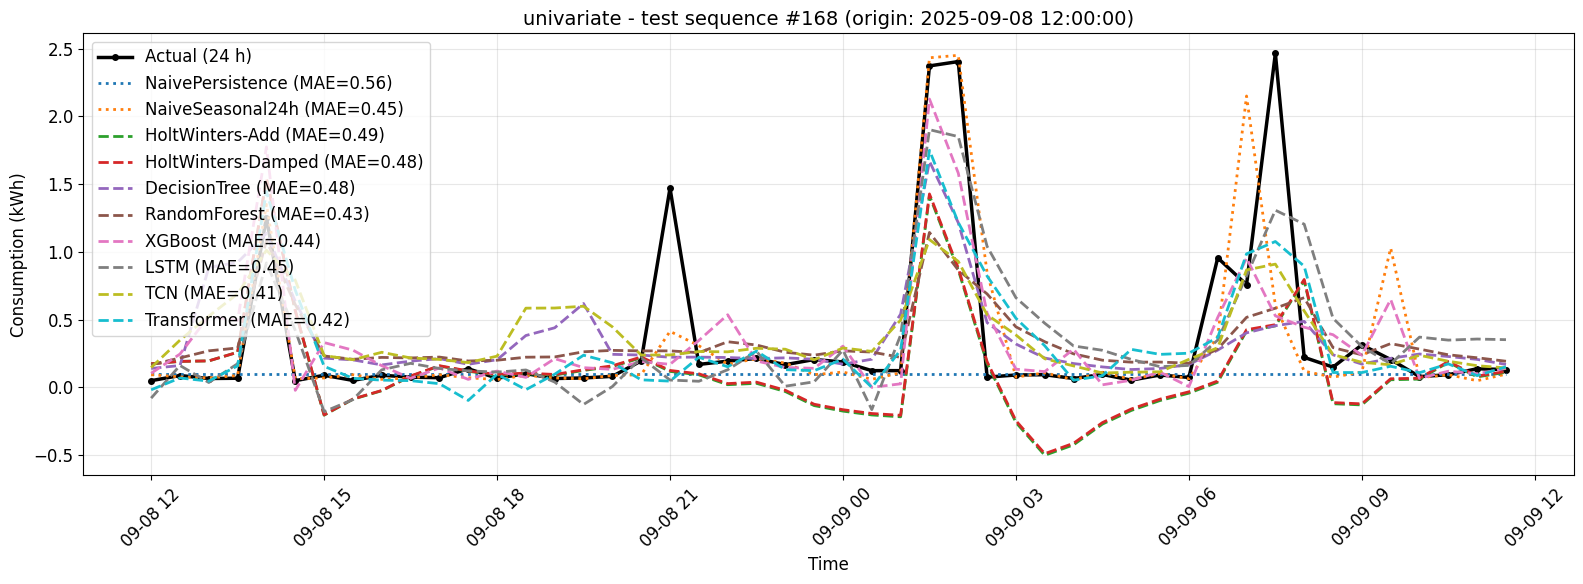

In [ ]:
data_uni, res_uni, preds_uni = run_config('univariate')



Configuration: seasonal (7 features)

  [Naive baselines]
  NaivePersistence     RMSE: 0.943  MAE: 0.561  MAPE: 159.87% (excl 7.2%)  sMAPE: 69.28%
  NaiveSeasonal24h     RMSE: 0.764  MAE: 0.445  MAPE: 131.50% (excl 7.2%)  sMAPE: 62.97%
  NaiveSeasonal48h     (evaluated on 5233/5281 sequences)
  NaiveSeasonal48h     RMSE: 0.831  MAE: 0.518  MAPE: 168.63% (excl 7.2%)  sMAPE: 75.42%

  [Statistical baseline] Holt-Winters
  Fitting HoltWinters-Add...
    params [0.473, 0.001, 0.172]  SSE=4766.0  fit 4.2s
  Fitting HoltWinters-Damped...
    params [0.473, 0.001, 0.172, 0.500]  SSE=4760.6  fit 5.0s
  HoltWinters-Add      RMSE: 0.727  MAE: 0.488  MAPE: 168.97% (excl 7.2%)  sMAPE: 92.96%
  HoltWinters-Damped   RMSE: 0.720  MAE: 0.484  MAPE: 167.23% (excl 7.2%)  sMAPE: 92.17%

  [Tree] Training DecisionTree...
  DecisionTree         RMSE: 0.694  MAE: 0.443  MAPE: 134.87% (excl 7.2%)  sMAPE: 73.49%
      profile: size ~0.05 MB, latency 0.15 ms, training 3.2 s

  [Tree] Training RandomForest...


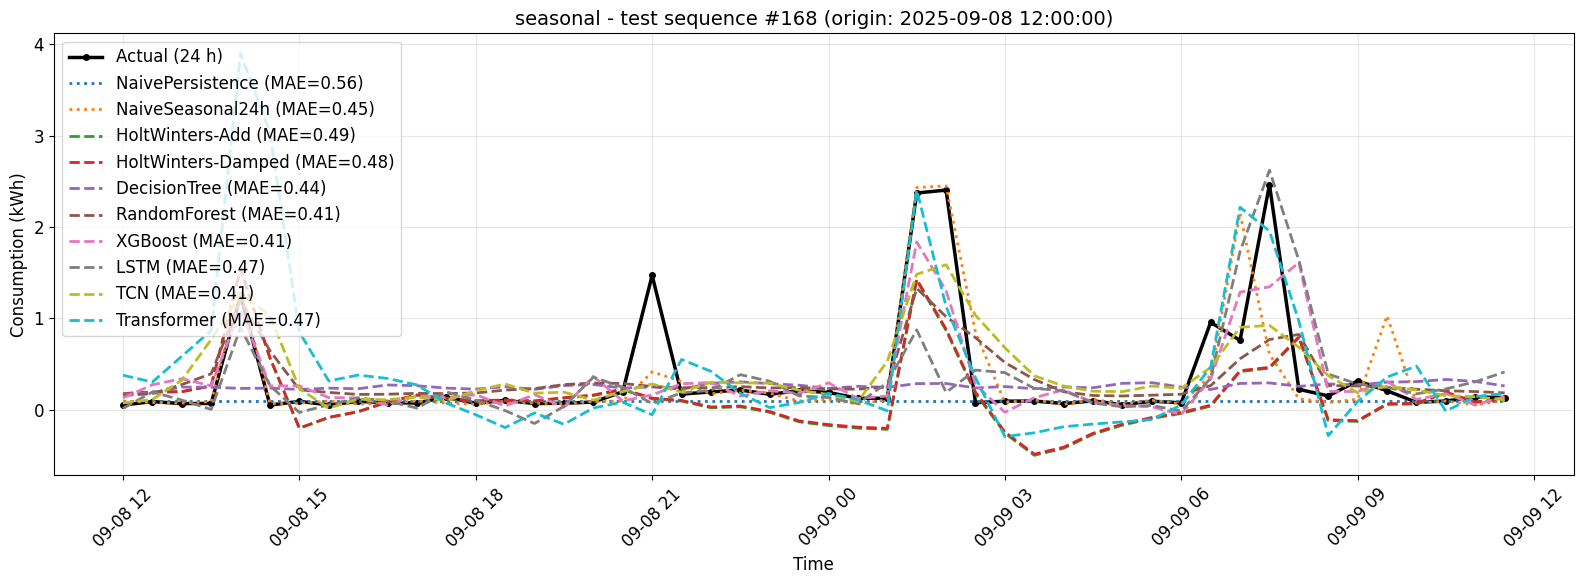

In [ ]:
data_seas, res_seas, preds_seas = run_config('seasonal')



Configuration: full (13 features)

  [Naive baselines]
  NaivePersistence     RMSE: 0.943  MAE: 0.561  MAPE: 159.87% (excl 7.2%)  sMAPE: 69.28%
  NaiveSeasonal24h     RMSE: 0.764  MAE: 0.445  MAPE: 131.50% (excl 7.2%)  sMAPE: 62.97%
  NaiveSeasonal48h     (evaluated on 5233/5281 sequences)
  NaiveSeasonal48h     RMSE: 0.831  MAE: 0.518  MAPE: 168.63% (excl 7.2%)  sMAPE: 75.42%

  [Statistical baseline] Holt-Winters
  Fitting HoltWinters-Add...
    params [0.473, 0.001, 0.172]  SSE=4766.0  fit 2.9s
  Fitting HoltWinters-Damped...
    params [0.473, 0.001, 0.172, 0.500]  SSE=4760.6  fit 4.7s
  HoltWinters-Add      RMSE: 0.727  MAE: 0.488  MAPE: 168.97% (excl 7.2%)  sMAPE: 92.96%
  HoltWinters-Damped   RMSE: 0.720  MAE: 0.484  MAPE: 167.23% (excl 7.2%)  sMAPE: 92.17%

  [Tree] Training DecisionTree...
  DecisionTree         RMSE: 0.756  MAE: 0.500  MAPE: 132.71% (excl 7.2%)  sMAPE: 82.95%
      profile: size ~0.05 MB, latency 0.14 ms, training 12.6 s

  [Tree] Training RandomForest...
  

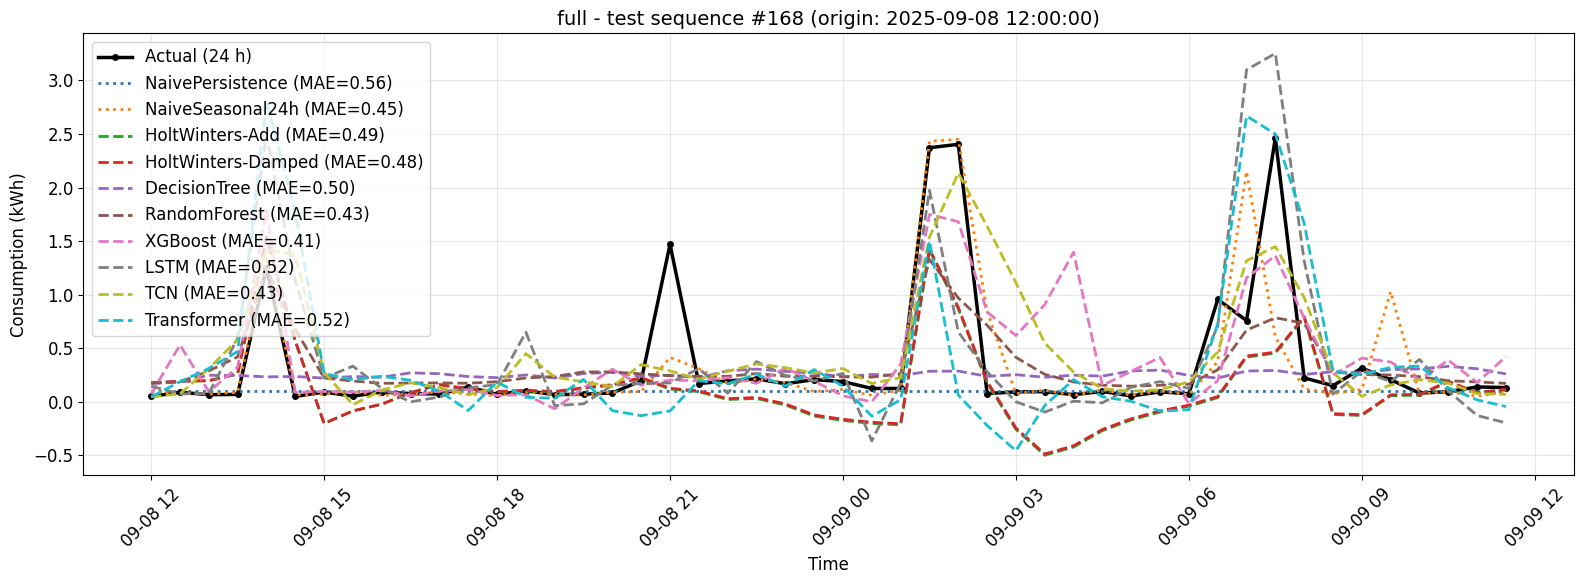

In [ ]:
data_full, res_full, preds_full = run_config('full')


## 6. Model and protocol specification

Complete hyperparameterization of every model of the study (this is the exact specification used for the paper — no per-configuration hyperparameter search was performed, as stated in the paper). All models share the same windows (48 past steps) and predict the 48 future steps at once; forecasts are clipped to be non-negative before any metric computation.


In [ ]:
HYPERPARAMS = {
    'DecisionTree':   {'library': 'scikit-learn', 'max_depth': 10, 'random_state': SEED},
    'RandomForest':   {'library': 'scikit-learn', 'n_estimators': 50, 'max_depth': 10,
                        'n_jobs': -1, 'random_state': SEED},
    'XGBoost':        {'library': 'xgboost (XGBRegressor)', 'n_estimators': 100, 'max_depth': 6,
                        'random_state': SEED,
                        'multi_output': 'the 48-step horizon is predicted in a single fit '
                                        '(native multi-output regression of the sklearn API)'},
    'LSTM':           {'library': 'PyTorch', 'hidden_size': 64, 'num_layers': 2, 'dropout': 0.2},
    'TCN':            {'library': 'PyTorch (custom blocks)', 'channels': '(64, 64, 64)',
                        'kernel_size': 3, 'dilations': '[1, 2, 4]', 'dropout': 0.2},
    'Transformer':    {'library': 'PyTorch (TransformerEncoder)', 'd_model': 64, 'nhead': 8,
                        'num_layers': 3, 'dim_feedforward': 256,
                        'positional_encoding': 'learned parameter (1, LOOKBACK, d_model)'},
    'HoltWinters':    {'implementation': 'self-contained additive recursion',
                        'seasonal_period': SEASONAL_PERIOD,
                        'parameter_estimation': 'direct SSE minimization, scipy L-BFGS-B, train segment only',
                        'update_protocol': 'online state update with frozen parameters, no re-estimation'},
}

TRAINING = {
    'optimizer': 'Adam', 'lr': LR, 'batch_size': BATCH_SIZE, 'epochs': EPOCHS,
    'loss': 'MSE', 'early_stopping': 'none (fixed 100 epochs, validation loss monitored)',
    'input_scaling': 'MinMaxScaler fitted on the training segment',
    'split': '60% train / 20% validation / 20% test, temporal, no shuffling',
    'non_negativity': 'clip to 0 applied uniformly before every metric',
}

display(pd.DataFrame(HYPERPARAMS).T)
display(pd.DataFrame([TRAINING]).T.rename(columns={0: 'value'}))


,library,max_depth,random_state,n_estimators,n_jobs,multi_output,hidden_size,num_layers,dropout,channels,kernel_size,dilations,d_model,nhead,dim_feedforward,positional_encoding,implementation,seasonal_period,parameter_estimation,update_protocol
DecisionTree,scikit-learn,10,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RandomForest,scikit-learn,10,42,50,-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
XGBoost,xgboost (XGBRegressor),6,42,100,NaN,the 48-step horizon is predicted in a single f...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LSTM,PyTorch,NaN,NaN,NaN,NaN,NaN,64,2,0.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TCN,PyTorch (custom blocks),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2,"(64, 64, 64)",3,"[1, 2, 4]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transformer,PyTorch (TransformerEncoder),NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,64,8,256,"learned parameter (1, LOOKBACK, d_model)",NaN,NaN,NaN,NaN
HoltWinters,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,self-contained additive recursion,48,"direct SSE minimization, scipy L-BFGS-B, train...","online state update with frozen parameters, no..."


,value
optimizer,Adam
lr,0.001
batch_size,64
epochs,100
loss,MSE
early_stopping,"none (fixed 100 epochs, validation loss monito..."
input_scaling,MinMaxScaler fitted on the training segment
split,"60% train / 20% validation / 20% test, tempora..."
non_negativity,clip to 0 applied uniformly before every metric


## 7. Paper figures

All figures use the same forecast origin `FIG_INDEX` for comparability.


seq #0 | origin 2025-09-05 00:00:00 | last observed value: 0.116 kWh | persistence level: 0.116 kWh
seq #168 | origin 2025-09-08 12:00:00 | last observed value: 0.098 kWh | persistence level: 0.098 kWh
seq #2000 | origin 2025-10-16 16:00:00 | last observed value: 0.090 kWh | persistence level: 0.090 kWh


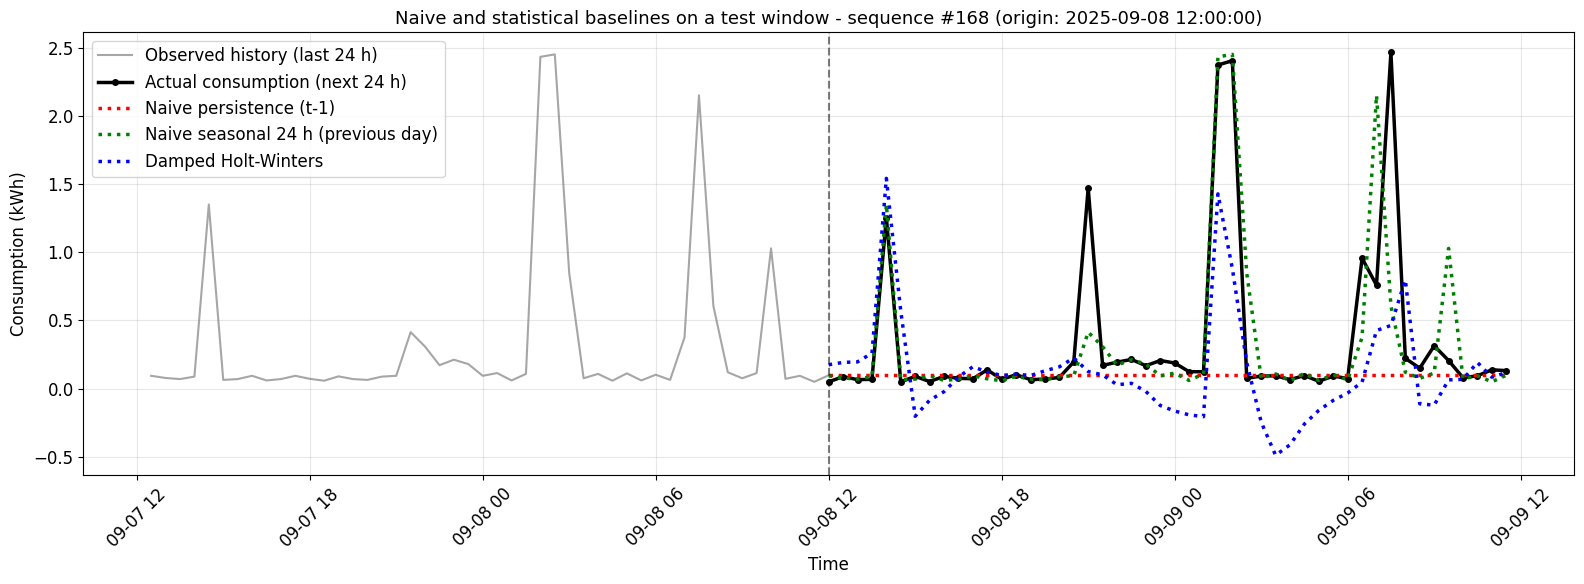

In [ ]:
# ----- Figure: naive and statistical baselines on a 24-hour test window -----
cfg = 'univariate'
_, _, test_full, _ = temporal_split(df_consumption[[TARGET_COL]])
val_tail = df_consumption[[TARGET_COL]].iloc[-LOOKBACK - len(test_full):].iloc[:LOOKBACK]
series = pd.concat([val_tail, test_full])[TARGET_COL].values

truth = all_truth[cfg]
preds = all_predictions[cfg]

for idx in [0, FIG_INDEX, 2000]:
    if idx >= truth.shape[0]:
        continue
    last_obs = series[LOOKBACK + idx - 1]
    print("seq #%d | origin %s | last observed value: %.3f kWh | persistence level: %.3f kWh"
          % (idx, test_full.index[idx], last_obs, preds['NaivePersistence'][idx, 0]))

idx = FIG_INDEX
if idx < truth.shape[0]:
    hist_kwh = series[idx : LOOKBACK + idx]
    times_hist = pd.date_range(end=test_full.index[idx], periods=LOOKBACK, freq='30min')
    times_fc = pd.date_range(start=test_full.index[idx], periods=HORIZON, freq='30min')
    plt.figure(figsize=(16, 6))
    plt.plot(times_hist, hist_kwh, '-', color='gray', alpha=0.7, label='Observed history (last 24 h)')
    plt.plot(times_fc, truth[idx], 'k-', linewidth=2.5, marker='o', markersize=4,
             label='Actual consumption (next 24 h)')
    plt.plot(times_fc, preds['NaivePersistence'][idx], ':', color='red', linewidth=2.5,
             label='Naive persistence (t-1)')
    plt.plot(times_fc, preds['NaiveSeasonal24h'][idx], ':', color='green', linewidth=2.5,
             label='Naive seasonal 24 h (previous day)')
    plt.plot(times_fc, preds['HoltWinters-Damped'][idx], ':', color='blue', linewidth=2.5,
             label='Damped Holt-Winters')
    plt.axvline(test_full.index[idx], color='black', linestyle='--', alpha=0.5)
    plt.title('Naive and statistical baselines on a test window - sequence #%d (origin: %s)'
              % (idx, test_full.index[idx]))
    plt.ylabel('Consumption (kWh)')
    plt.xlabel('Time')
    plt.legend(loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('fig_baselines.png', dpi=300, bbox_inches='tight')
    plt.show()


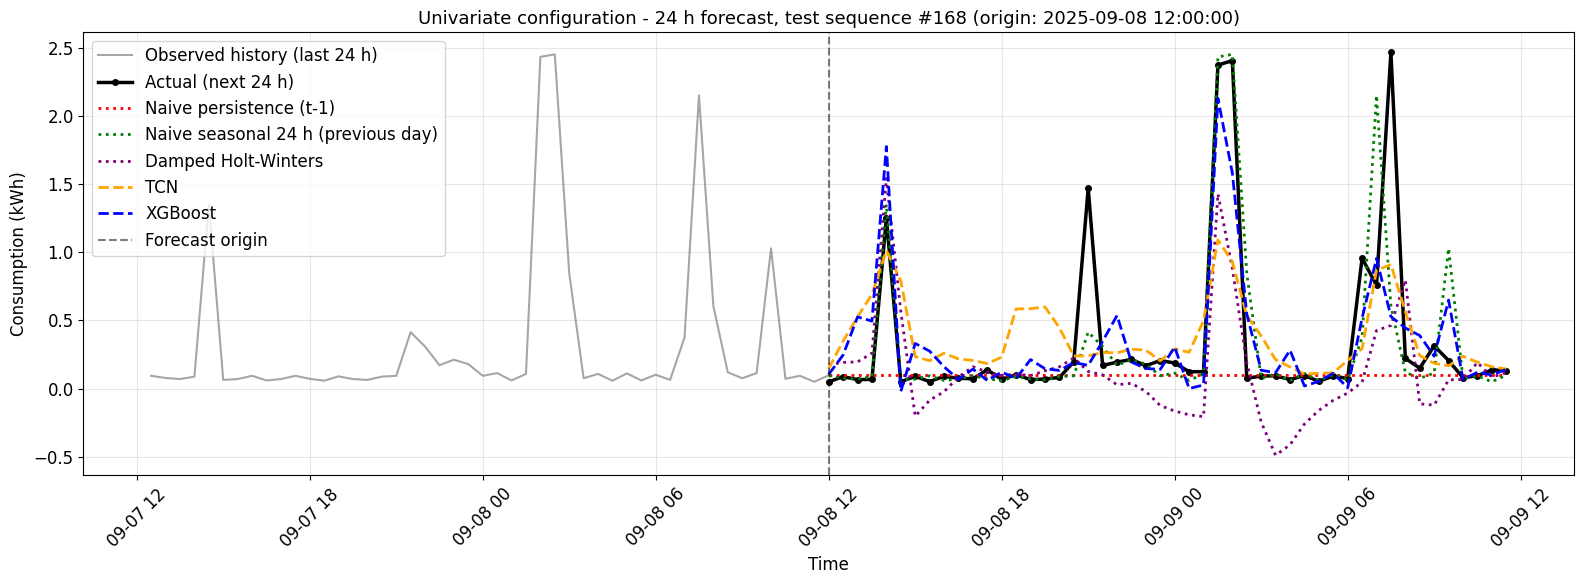

In [ ]:
# ----- Figure: 24 h forecast on a test day, univariate configuration -----
# Actual consumption, naive and statistical baselines, TCN and XGBoost.

CFG = 'univariate'
IDX = FIG_INDEX   # same origin as the other figures

_, _, test_full, _ = temporal_split(df_consumption[[TARGET_COL]])
val_tail = df_consumption[[TARGET_COL]].iloc[-LOOKBACK - len(test_full):].iloc[:LOOKBACK]
series = pd.concat([val_tail, test_full])[TARGET_COL].values

truth = all_truth[CFG]
preds = all_predictions[CFG]
assert IDX < truth.shape[0], 'IDX out of range (max %d)' % (truth.shape[0] - 1)

hist_kwh = series[IDX : LOOKBACK + IDX]
times_hist = pd.date_range(end=test_full.index[IDX], periods=LOOKBACK, freq='30min')
times_fc = pd.date_range(start=test_full.index[IDX], periods=HORIZON, freq='30min')

plt.figure(figsize=(16, 6))
plt.plot(times_hist, hist_kwh, '-', color='gray', alpha=0.7, label='Observed history (last 24 h)')
plt.plot(times_fc, truth[IDX], 'k-', linewidth=2.5, marker='o', markersize=4, label='Actual (next 24 h)')
plt.plot(times_fc, preds['NaivePersistence'][IDX], ':', color='red', linewidth=2, label='Naive persistence (t-1)')
plt.plot(times_fc, preds['NaiveSeasonal24h'][IDX], ':', color='green', linewidth=2, label='Naive seasonal 24 h (previous day)')
plt.plot(times_fc, preds['HoltWinters-Damped'][IDX], ':', color='purple', linewidth=2, label='Damped Holt-Winters')
plt.plot(times_fc, preds['TCN'][IDX], '--', color='orange', linewidth=2, label='TCN')
plt.plot(times_fc, preds['XGBoost'][IDX], '--', color='blue', linewidth=2, label='XGBoost')
plt.axvline(test_full.index[IDX], color='black', linestyle='--', alpha=0.5, label='Forecast origin')
plt.title('Univariate configuration - 24 h forecast, test sequence #%d (origin: %s)'
          % (IDX, test_full.index[IDX]))
plt.ylabel('Consumption (kWh)')
plt.xlabel('Time')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig_forecast_uni.png', dpi=300, bbox_inches='tight')
plt.show()


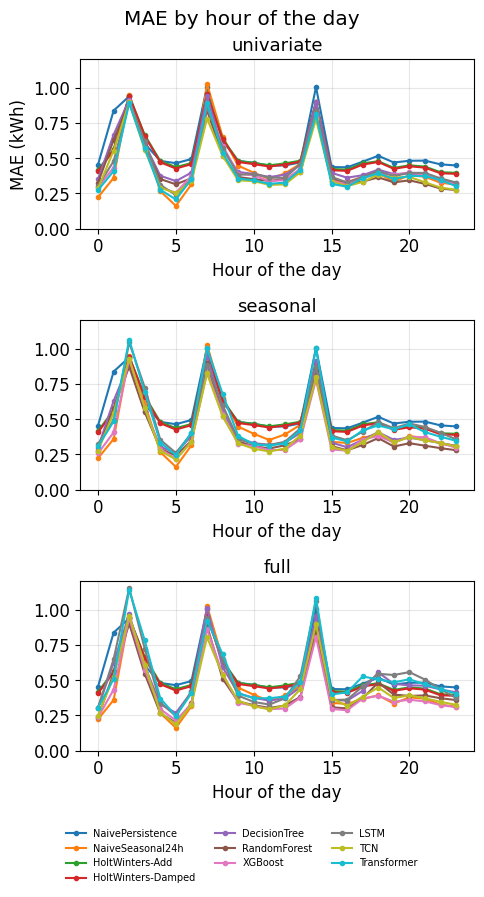

In [ ]:
# ----- Figure: MAE by hour of the day, three configurations -----
ANALYSIS_MODELS = ['NaivePersistence', 'NaiveSeasonal24h'] + STAT_ORDER + MODEL_ORDER

def seq_origin_times(test_df, n_seq):
    """The origin of sequence idx is test[idx] (no shift)."""
    return test_df.index[:n_seq]

hour_rows = []
for cfg in FEATURE_SETS:
    truth = all_truth[cfg]
    n_seq, horizon = truth.shape
    origins = seq_origin_times(data_uni['test_df'], n_seq)
    for model in ANALYSIS_MODELS:
        pred = all_predictions[cfg].get(model)
        if pred is None:
            continue
        abs_err = np.abs(truth - pred)  # (n_seq, horizon)
        step_offsets = np.array([np.timedelta64(30 * h, 'm') for h in range(horizon)])
        real_times = origins.to_numpy().astype('datetime64[m]')[:, None] + step_offsets[None, :]
        hour_matrix = (real_times.astype('datetime64[h]').astype(int)) % 24
        for hour in range(24):
            mask = hour_matrix == hour
            if mask.sum() == 0:
                continue
            hour_rows.append({'config': cfg, 'model': model, 'hour': hour,
                              'mae': float(abs_err[mask].mean())})
df_hour = pd.DataFrame(hour_rows)

fig, axes = plt.subplots(3, 1, figsize=(5, 9), sharey=True)
for ax, cfg in zip(axes, FEATURE_SETS):
    sub = df_hour[df_hour['config'] == cfg]
    for model in ANALYSIS_MODELS:
        s = sub[sub['model'] == model].sort_values('hour')
        ax.plot(s['hour'], s['mae'], marker='o', markersize=3, label=model)
    ax.set_title(cfg)
    ax.set_xlabel('Hour of the day')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('MAE (kWh)')
axes[0].set_ylim(bottom=0)

handles, labels = axes[-1].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.08, 1, 0.97))
fig.suptitle('MAE by hour of the day')
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=7,
           frameon=False, bbox_to_anchor=(0.5, 0.0))
plt.savefig('fig_hourly_mae.png', dpi=300, bbox_inches='tight')
plt.show()


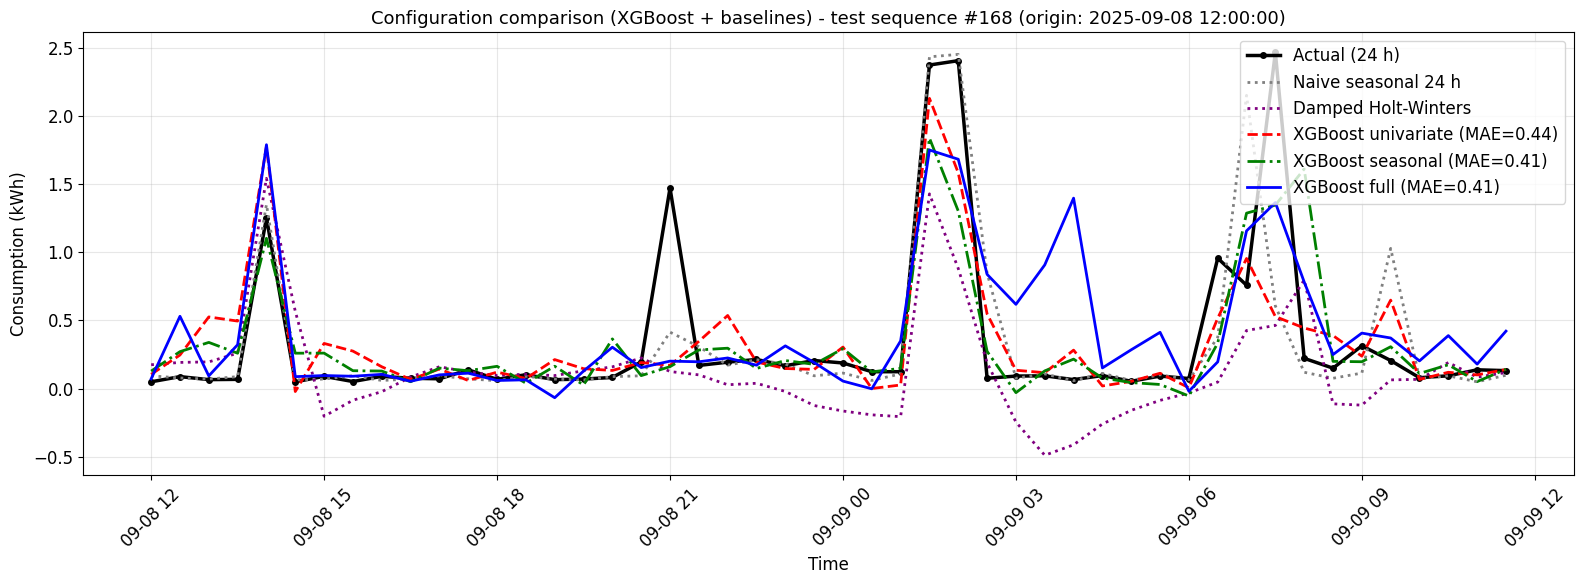

In [ ]:
# ----- Figure: cross-configuration comparison (XGBoost + baselines) -----
idx = FIG_INDEX
plt.figure(figsize=(16, 6))
times = sequence_timestamps(data_uni['test_df'], idx)
plt.plot(times, all_truth['univariate'][idx], 'k-', linewidth=2.5, marker='o',
         markersize=4, label='Actual (24 h)')
plt.plot(times, all_predictions['univariate']['NaiveSeasonal24h'][idx], ':',
         color='gray', linewidth=2, label='Naive seasonal 24 h')
plt.plot(times, all_predictions['univariate']['HoltWinters-Damped'][idx], ':',
         color='purple', linewidth=2, label='Damped Holt-Winters')
styles = {'univariate': 'r--', 'seasonal': 'g-.', 'full': 'b-'}
for cfg, style in styles.items():
    m = all_results[cfg]['XGBoost']
    plt.plot(times, all_predictions[cfg]['XGBoost'][idx], style, linewidth=2,
             label='XGBoost %s (MAE=%.2f)' % (cfg, m['mae']))
plt.title('Configuration comparison (XGBoost + baselines) - test sequence #%d (origin: %s)'
          % (idx, times[0]))
plt.ylabel('Consumption (kWh)')
plt.xlabel('Time')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('fig_config_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


## 8. Summary table (paper Tables 1–4)

Metrics, 95% bootstrap confidence intervals and Diebold-Mariano statistics against the naive seasonal 24h baseline, for the three configurations.


In [ ]:
rows = []
for cfg in FEATURE_SETS:
    for name in BASELINE_ORDER + STAT_ORDER + MODEL_ORDER:
        if name not in all_results[cfg]:
            continue
        m = all_results[cfg][name]
        ci_rmse = all_ci[cfg].get(name, {}).get('rmse', (np.nan, np.nan))
        ci_mae = all_ci[cfg].get(name, {}).get('mae', (np.nan, np.nan))
        dm = all_dm[cfg].get(name, {})
        rows.append({
            'config': cfg, 'model': name,
            'RMSE': m['rmse'], 'RMSE_CI_lo': ci_rmse[0], 'RMSE_CI_hi': ci_rmse[1],
            'MAE': m['mae'], 'MAE_CI_lo': ci_mae[0], 'MAE_CI_hi': ci_mae[1],
            'MAPE_%': m['mape'] * 100, 'sMAPE_%': m['smape'] * 100,
            'MAPE_excl_%': m['mape_excl'] * 100,
            'DM_vs_Naive24h': dm.get('dm_stat', np.nan),
            'DM_p_value': dm.get('p_value', np.nan),
        })
summary = pd.DataFrame(rows)
display(summary.round(3))
summary.to_csv('results_summary.csv', index=False)
print('Table exported: results_summary.csv')


,config,model,RMSE,RMSE_CI_lo,RMSE_CI_hi,MAE,MAE_CI_lo,MAE_CI_hi,MAPE_%,sMAPE_%,MAPE_excl_%,DM_vs_Naive24h,DM_p_value
0,univariate,NaivePersistence,0.943,0.922,0.961,0.561,0.548,0.574,159.870,69.280,7.163,NaN,NaN
1,univariate,NaiveSeasonal24h,0.764,0.754,0.775,0.445,0.438,0.452,131.503,62.966,7.163,NaN,NaN
2,univariate,NaiveSeasonal48h,0.831,NaN,NaN,0.518,NaN,NaN,168.634,75.422,7.190,NaN,NaN
3,univariate,HoltWinters-Add,0.727,0.713,0.739,0.488,0.480,0.497,168.972,92.960,7.163,-2.498,0.013
4,univariate,HoltWinters-Damped,0.720,0.706,0.732,0.484,0.475,0.492,167.235,92.171,7.163,-4.232,0.000
5,univariate,DecisionTree,0.727,0.717,0.736,0.477,0.470,0.484,161.068,74.486,7.163,-10.917,0.000
6,univariate,RandomForest,0.647,0.638,0.656,0.434,0.428,0.440,154.347,72.812,7.163,-38.247,0.000
7,univariate,XGBoost,0.658,0.648,0.667,0.436,0.431,0.442,156.159,70.978,7.163,-35.496,0.000
8,univariate,LSTM,0.699,0.688,0.709,0.445,0.438,0.453,146.983,74.154,7.163,-16.925,0.000
9,univariate,TCN,0.626,0.617,0.636,0.415,0.409,0.421,146.527,69.052,7.163,-43.424,0.000


Table exported: results_summary.csv


### 8.1 Model profiling (edge deployment perspective)

Caveat: latencies are measured on the current execution hardware (single-window inference, mean over 100 calls). They are indicative of the orders of magnitude only — in particular, the Holt-Winters latency is profiled over a full batch of origins, not a single window, and is therefore not directly comparable with the other models. Memory footprints of tree models are estimated from node counts.


In [ ]:
prof_rows = []
for cfg in FEATURE_SETS:
    for model in STAT_ORDER + MODEL_ORDER:
        p = all_profiles[cfg].get(model)
        if p:
            prof_rows.append({'config': cfg, 'model': model,
                              'params': p.get('params'), 'size_mb': p.get('size_mb'),
                              'latency_ms': p.get('latency_ms'), 'train_s': p.get('train_s')})
df_prof = pd.DataFrame(prof_rows)
display(df_prof.round(3))
df_prof.to_csv('profiling_summary.csv', index=False)
print('Table exported: profiling_summary.csv')


,config,model,params,size_mb,latency_ms,train_s
0,univariate,HoltWinters-Add,53.0,0.000,72.308,2.917
1,univariate,HoltWinters-Damped,54.0,0.000,75.202,4.727
2,univariate,DecisionTree,NaN,0.053,0.133,1.164
3,univariate,RandomForest,NaN,2.484,22.458,30.880
4,univariate,XGBoost,NaN,2.289,1.882,73.644
5,univariate,LSTM,53552.0,0.204,0.266,83.264
6,univariate,TCN,65648.0,0.250,1.201,140.908
7,univariate,Transformer,156272.0,0.596,1.731,231.333
8,seasonal,HoltWinters-Add,53.0,0.000,55.790,4.186
9,seasonal,HoltWinters-Damped,54.0,0.000,65.852,5.015


Table exported: profiling_summary.csv


## 9. Paired significance tests (between configurations and between models)

The DM tests of section 4 compare each model with the naive seasonal 24h baseline. The tests below are the paired comparisons discussed in the paper: (i) the same model across feature configurations (does the enrichment help or hurt this model?), and (ii) the leading models against each other within the seasonal configuration (are TCN, XGBoost and Random Forest statistically distinguishable?). A negative statistic means the first model has a lower loss.


In [ ]:
paired_rows = []
truth = all_truth['univariate']   # identical across configurations (same target windows)

# (i) Cross-configuration, per model
pairs = [('seasonal', 'univariate'), ('full', 'seasonal'), ('full', 'univariate')]
for model in MODEL_ORDER:
    for a, b in pairs:
        pa, pb = all_predictions[a].get(model), all_predictions[b].get(model)
        if pa is None or pb is None:
            continue
        stat, p = diebold_mariano(truth, pa, pb, loss='squared')
        verdict = ('%s better' % a if (stat < 0 and p < 0.05)
                  else ('%s better' % b if (stat > 0 and p < 0.05) else 'not significant'))
        paired_rows.append({'test': 'cross-configuration', 'model': model,
                            'A': a, 'B': b, 'DM': stat, 'p_value': p, 'verdict': verdict})

# (ii) Between leading models, seasonal configuration
cfg = 'seasonal'
for a, b in [('TCN', 'XGBoost'), ('TCN', 'RandomForest'), ('XGBoost', 'RandomForest')]:
    stat, p = diebold_mariano(truth, all_predictions[cfg][a], all_predictions[cfg][b], loss='squared')
    verdict = ('%s better' % a if (stat < 0 and p < 0.05)
              else ('%s better' % b if (stat > 0 and p < 0.05) else 'not significant'))
    paired_rows.append({'test': 'between-models (%s)' % cfg, 'model': '%s vs %s' % (a, b),
                        'A': a, 'B': b, 'DM': stat, 'p_value': p, 'verdict': verdict})

df_paired = pd.DataFrame(paired_rows)
display(df_paired.round(4))
df_paired.to_csv('paired_tests.csv', index=False)
print('Table exported: paired_tests.csv')


,test,model,A,B,DM,p_value,verdict
0,cross-configuration,DecisionTree,seasonal,univariate,-10.2827,0.0000,seasonal better
1,cross-configuration,DecisionTree,full,seasonal,16.4681,0.0000,seasonal better
2,cross-configuration,DecisionTree,full,univariate,7.3393,0.0000,univariate better
3,cross-configuration,RandomForest,seasonal,univariate,-12.0542,0.0000,seasonal better
4,cross-configuration,RandomForest,full,seasonal,12.1427,0.0000,seasonal better
5,cross-configuration,RandomForest,full,univariate,6.1419,0.0000,univariate better
6,cross-configuration,XGBoost,seasonal,univariate,-23.7126,0.0000,seasonal better
7,cross-configuration,XGBoost,full,seasonal,7.7222,0.0000,seasonal better
8,cross-configuration,XGBoost,full,univariate,-11.3470,0.0000,full better
9,cross-configuration,LSTM,seasonal,univariate,9.4080,0.0000,univariate better


Table exported: paired_tests.csv


## 10. Reproducibility notes

- Seeds are fixed (`SEED = 42`) for NumPy and PyTorch; tree models use `random_state=SEED`. Remaining variability comes from hardware and library versions.
- `results_summary.csv`, `profiling_summary.csv` and `paired_tests.csv` are re-generated by this notebook; the versions corresponding to the paper's run are provided in the repository for comparison.
- The MAPE is reported only after excluding test steps whose true consumption is below 0.05 kWh (about 7% of the test steps); the exclusion rate is recomputed and printed in the summary table.
